<a href="https://colab.research.google.com/github/GOKUL31-P/Deep-leraning/blob/main/Assignment2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

84125825/84125825 ━━━━━━━━━━━━━━━━━━━━ 22s 0us/step
IMDB Dataset Downloaded Successfully!
Training Reviews: 25000
Testing Reviews: 25000
Tokenization Completed!
Example Tokens:
[396, 21, 2, 1928, 7, 33, 8927, 1665, 9458, 20, 15, 62, 165, 5622, 98, 26, 222, 10, 2, 18]
Training Data Shape: (25000, 300)
Testing Data Shape: (25000, 300)

LSTM MODEL SUMMARY


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

... (3 outputs left out)

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 121s 750ms/step - accuracy: 0.6239 - loss: 0.6642 - val_accuracy: 0.0000e+00 - val_loss: 0.9819
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 116s 741ms/step - accuracy: 0.6252 - loss: 0.6543 - val_accuracy: 0.0012 - val_loss: 1.0417
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 116s 742ms/step - accuracy: 0.6576 - loss: 0.6129 - val_accuracy: 0.0824 - val_loss: 1.1288
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 116s 738ms/step - accuracy: 0.6912 - loss: 0.5511 - val_accuracy: 0.0954 - val_loss: 1.2281
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 116s 742ms/step - accuracy: 0.7653 - loss: 0.4623 - val_accuracy: 0.7710 - val_loss: 0.6133
782/782 ━━━━━━━━━━━━━━━━━━━━ 36s 47ms/step - accuracy: 0.8013 - loss: 0.5026

GRU RESULTS
Test Loss: 0.5026346445083618
Test Accuracy: 80.12800216674805 %
782/782 ━━━━━━━━━━━━━━━━━━━━ 37s 47ms/step

GRU CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative       0.82      0.78      0.80     12500
    Pos

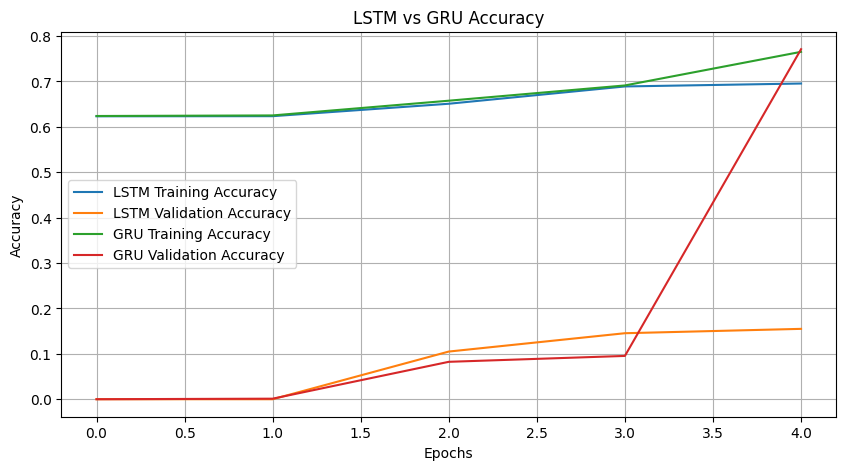

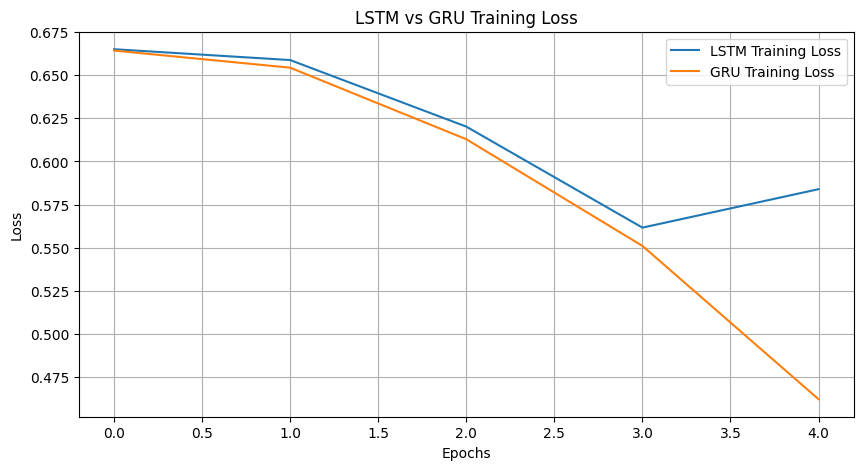

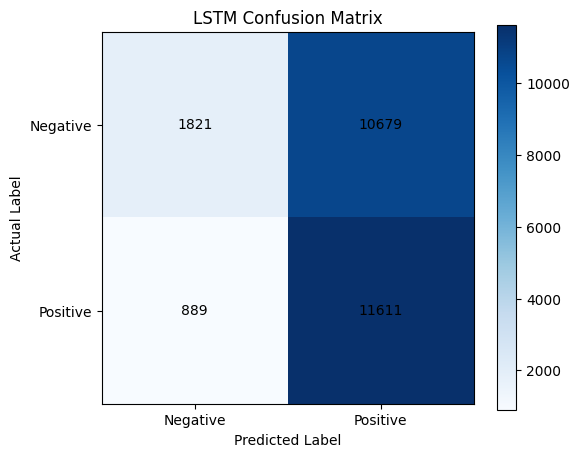

Sentiment: POSITIVE
Prediction Score: 0.5780834
Sentiment: POSITIVE
Prediction Score: 0.5780834

NLP EXPERIMENT COMPLETED SUCCESSFULLY!


In [17]:
# ==========================================================
# SEQUENCE MODELING FOR NATURAL LANGUAGE PROCESSING (NLP)
# IMDB MOVIE REVIEW SENTIMENT ANALYSIS USING LSTM AND GRU
# ==========================================================
# 1. IMPORT LIBRARIES
import os
import tarfile
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, GRU
from tensorflow.keras.layers import Dense, Dropout, Bidirectional
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
# 2. DOWNLOAD IMDB DATASET
url ="https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz"
dataset_path = tf.keras.utils.get_file(
"aclImdb_v1.tar.gz",
origin=url,
extract=False
)
extract_path = Path("/content/aclImdb")
if not extract_path.exists():
with tarfile.open(dataset_path, "r:gz") as tar:
tar.extractall(path="/content")
print("IMDB Dataset Downloaded Successfully!")
# 3. LOAD RAW TEXT DATA
def load_reviews(folder):
reviews = []
labels = []
for sentiment, label in [("pos", 1), ("neg", 0)]:

folder_path = Path(folder) / sentiment
for file in folder_path.glob("*.txt"):
with open(file, "r", encoding="utf-8") as f:
text = f.read()
reviews.append(text)
labels.append(label)
return reviews, labels
train_reviews, train_labels = load_reviews(
"/content/aclImdb/train"
)
test_reviews, test_labels = load_reviews(
"/content/aclImdb/test"
)
print("Training Reviews:", len(train_reviews))
print("Testing Reviews:", len(test_reviews))
# 4. CONVERT INTO NUMPY ARRAYS
train_labels = np.array(train_labels)
test_labels = np.array(test_labels)
# 5. TOKENIZATION
vocab_size = 20000
tokenizer = Tokenizer(
num_words=vocab_size,
oov_token="<OOV>"
)
tokenizer.fit_on_texts(train_reviews)
X_train = tokenizer.texts_to_sequences(train_reviews)
X_test = tokenizer.texts_to_sequences(test_reviews)
print("Tokenization Completed!")
print("Example Tokens:")
print(X_train[0][:20])
# 6. TEXT PADDING

max_length = 300
X_train = pad_sequences(
X_train,
maxlen=max_length,
padding="post",
truncating="post"
)
X_test = pad_sequences(
X_test,
maxlen=max_length,
padding="post",
truncating="post"
)
print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)
# 7. BUILD LSTM MODEL
lstm_model = Sequential([
Embedding(
input_dim=vocab_size,
output_dim=128,
input_length=max_length
),
LSTM(64),
Dropout(0.5),
Dense(32, activation="relu"),
Dense(1, activation="sigmoid")
])
lstm_model.compile(
optimizer="adam",
loss="binary_crossentropy",
metrics=["accuracy"]
)
print("\nLSTM MODEL SUMMARY")
lstm_model.summary()
# 8. TRAIN LSTM MODEL
lstm_history = lstm_model.fit(
X_train,

train_labels,
epochs=5,
batch_size=128,
validation_split=0.2,
verbose=1
)
# 9. EVALUATE LSTM MODEL
lstm_loss, lstm_accuracy = lstm_model.evaluate(
X_test,
test_labels,
verbose=1
)
print("\nLSTM RESULTS")
print("Test Loss:", lstm_loss)
print("Test Accuracy:", lstm_accuracy * 100, "%")
# 10. LSTM PREDICTION
lstm_predictions = lstm_model.predict(X_test)
lstm_classes = (
lstm_predictions > 0.5
).astype(int).flatten()
print("\nLSTM CLASSIFICATION REPORT")
print(
classification_report(
test_labels,
lstm_classes,
target_names=["Negative", "Positive"]
)
)
# 11. BUILD GRU MODEL
gru_model = Sequential([
Embedding(
input_dim=vocab_size,
output_dim=128,
input_length=max_length
),
GRU(64),
Dropout(0.5),

Dense(32, activation="relu"),
Dense(1, activation="sigmoid")
])
gru_model.compile(
optimizer="adam",
loss="binary_crossentropy",
metrics=["accuracy"]
)
print("\nGRU MODEL SUMMARY")
gru_model.summary()
# 12. TRAIN GRU MODEL
gru_history = gru_model.fit(
X_train,
train_labels,
epochs=5,
batch_size=128,
validation_split=0.2,
verbose=1
)
# 13. EVALUATE GRU MODEL
gru_loss, gru_accuracy = gru_model.evaluate(
X_test,
test_labels,
verbose=1
)
print("\nGRU RESULTS")
print("Test Loss:", gru_loss)
print("Test Accuracy:", gru_accuracy * 100, "%")
# 14. GRU PREDICTION
gru_predictions = gru_model.predict(X_test)
gru_classes = (
gru_predictions > 0.5
).astype(int).flatten()
print("\nGRU CLASSIFICATION REPORT")
print(
classification_report(
test_labels,

gru_classes,
target_names=["Negative", "Positive"]
)
)
# 15. COMPARE LSTM AND GRU
print("\nMODEL COMPARISON")
print("LSTM Accuracy:", lstm_accuracy * 100, "%")
print("GRU Accuracy:", gru_accuracy * 100, "%")
# 16. PLOT ACCURACY COMPARISON
plt.figure(figsize=(10, 5))
plt.plot(
lstm_history.history["accuracy"],
label="LSTM Training Accuracy"
)
plt.plot(
lstm_history.history["val_accuracy"],
label="LSTM Validation Accuracy"
)
plt.plot(
gru_history.history["accuracy"],
label="GRU Training Accuracy"
)
plt.plot(
gru_history.history["val_accuracy"],
label="GRU Validation Accuracy"
)
plt.title("LSTM vs GRU Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()
# 17. PLOT LOSS COMPARISON
plt.figure(figsize=(10, 5))
plt.plot(
lstm_history.history["loss"],
label="LSTM Training Loss"

)
plt.plot(
gru_history.history["loss"],
label="GRU Training Loss"
)
plt.title("LSTM vs GRU Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()
# 18. CONFUSION MATRIX FOR LSTM
cm = confusion_matrix(test_labels, lstm_classes)
plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")
plt.title("LSTM Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks([0, 1], ["Negative", "Positive"])
plt.yticks([0, 1], ["Negative", "Positive"])
for i in range(2):
for j in range(2):
plt.text(j, i, cm[i, j],
ha="center", va="center")
plt.colorbar()
plt.show()
# 19. TEST WITH A NEW REVIEW
def predict_sentiment(review):
sequence = tokenizer.texts_to_sequences([review])
padded = pad_sequences(
sequence,
maxlen=max_length,
padding="post",
truncating="post"
)
prediction = lstm_model.predict(
padded,

verbose=0
)[0][0]
if prediction >= 0.5:
print("Sentiment: POSITIVE")
else:
print("Sentiment: NEGATIVE")
print("Prediction Score:", prediction)
# Example reviews
predict_sentiment(
"This movie was amazing and the acting was excellent"
)
predict_sentiment(
"This movie was boring and the story was terrible"
)
print("\nNLP EXPERIMENT COMPLETED SUCCESSFULLY!")